## Load Day 1 Training and Test Data

In this step, the project directory is identified and the required project folders are ensured to exist.

The training and test datasets saved during Day 1 are loaded from the `data` directory so that the same data split can be reused for Day 3 model tuning and evaluation.

The `src` directory is also added to the Python path so that reusable project modules can be imported.

Finally, the datasets are separated into:

- `xtrain` - Training features
- `ytrain` - Training target (`Churn`)
- `xtest` - Test features
- `ytest` - Test target (`Churn`)

Using the same training and test data keeps model evaluation consistent across the different RetailMind iterations.

In [63]:
import pandas as pd
import numpy as np
import joblib

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# import matplotlib.pyplot as plt

In [64]:
BASE_DIR = Path.cwd()

if not (BASE_DIR / "data").exists():
    BASE_DIR = BASE_DIR.parent

training_data_path = BASE_DIR / "data" / "train_data.csv"
test_data_path = BASE_DIR / "data" / "test_data.csv"


(BASE_DIR / "data").mkdir(parents=True, exist_ok=True)
(BASE_DIR / "models").mkdir(parents=True, exist_ok=True)
(BASE_DIR / "src").mkdir(parents=True, exist_ok=True)


In [65]:
train_data = pd.read_csv(training_data_path)
test_data = pd.read_csv(test_data_path)


print("Project directory:", BASE_DIR)


Project directory: /Users/apple/Desktop/timepass/RetailMind


In [66]:
import sys

sys.path.insert(0, str(BASE_DIR / "src"))

In [67]:
xtrain = train_data.drop("Churn", axis=1)
ytrain = train_data["Churn"]
xtest = test_data.drop("Churn", axis=1)
ytest = test_data["Churn"]
print("Training:", xtrain.shape)
print("Testing:", xtest.shape)

Training: (5634, 19)
Testing: (1409, 19)


## Cross-Validation Configuration

We use 5-fold Stratified Cross-Validation to preserve
the churn class distribution across all folds.

In [68]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [69]:
for fold, (train_idx, val_idx) in enumerate(
    cv.split(xtrain, ytrain),
    start=1
):
    y_fold_train = ytrain.iloc[train_idx]
    y_fold_val = ytrain.iloc[val_idx]

    print(f"\nFold {fold}")

    print(
        "Training churn proportion:",
        round(y_fold_train.mean(), 3)
    )

    print(
        "Validation churn proportion:",
        round(y_fold_val.mean(), 3)
    )


Fold 1
Training churn proportion: 0.265
Validation churn proportion: 0.265

Fold 2
Training churn proportion: 0.265
Validation churn proportion: 0.265

Fold 3
Training churn proportion: 0.265
Validation churn proportion: 0.265

Fold 4
Training churn proportion: 0.265
Validation churn proportion: 0.265

Fold 5
Training churn proportion: 0.265
Validation churn proportion: 0.266


In [70]:
def tune_model(model, param_grid, xtrain, ytrain):

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring="recall",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        return_train_score=True
    )

    grid_search.fit(xtrain, ytrain)

    return grid_search

In [71]:
decision_tree_grid = {
    "classifier__max_depth": [3, 5, 10, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10]
}

In [72]:
random_forest_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 20, None],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__max_features": ["sqrt", 0.5]
}

In [73]:
svm_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", "auto", 0.01, 0.1],
    "classifier__kernel": ["rbf"]
}

In [74]:
total_combinations = (
    len(list(__import__("itertools").product(
        decision_tree_grid["classifier__max_depth"],
        decision_tree_grid["classifier__min_samples_split"],
        decision_tree_grid["classifier__min_samples_leaf"]
    )))
    +
    len(list(__import__("itertools").product(
        random_forest_grid["classifier__n_estimators"],
        random_forest_grid["classifier__max_depth"],
        random_forest_grid["classifier__min_samples_split"],
        random_forest_grid["classifier__min_samples_leaf"],
        random_forest_grid["classifier__max_features"]
    )))
    +
    len(list(__import__("itertools").product(
        svm_grid["classifier__C"],
        svm_grid["classifier__gamma"],
        svm_grid["classifier__kernel"]
    )))
)

print("Total parameter combinations:", total_combinations)
print("Total model fits:", total_combinations * 5)

Total parameter combinations: 148
Total model fits: 740


In [75]:
parameter_grids = {
    "Decision Tree": decision_tree_grid,
    "Random Forest": random_forest_grid,
    "SVM": svm_grid
}

for name, grid in parameter_grids.items():
    print(f"{name}: {len(grid)} hyperparameters")

Decision Tree: 3 hyperparameters
Random Forest: 5 hyperparameters
SVM: 3 hyperparameters


In [76]:
tuning_results = {}

In [77]:
import sys

sys.path.insert(0, str(BASE_DIR / "src"))

from pipeline import build_pipeline

In [78]:
classifiers = {
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    )
}

In [79]:
models = {}

for name, classifier in classifiers.items():

    models[name] = build_pipeline(
        xtrain,
        classifier=classifier
    )

    print(f"{name} pipeline created successfully!")

Decision Tree pipeline created successfully!
Random Forest pipeline created successfully!
SVM pipeline created successfully!


In [80]:
decision_tree_search = tune_model(
    model=models["Decision Tree"],
    param_grid=decision_tree_grid,
    xtrain=xtrain,
    ytrain=ytrain
)

tuning_results["Decision Tree"] = decision_tree_search

Fitting 5 folds for each of 36 candidates, totalling 180 fits


In [81]:
print("Best parameters:")
print(decision_tree_search.best_params_)

print("\nBest cross-validation recall:")
print(decision_tree_search.best_score_)

Best parameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}

Best cross-validation recall:
0.7812709030100334


In [82]:
random_forest_search = tune_model(
    model=models["Random Forest"],
    param_grid=random_forest_grid,
    xtrain=xtrain,
    ytrain=ytrain
)

tuning_results["Random Forest"] = random_forest_search

Fitting 5 folds for each of 96 candidates, totalling 480 fits


In [83]:
print("Best parameters:")
print(random_forest_search.best_params_)

print("\nBest cross-validation recall:")
print(random_forest_search.best_score_)

Best parameters:
{'classifier__max_depth': 5, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 300}

Best cross-validation recall:
0.8066889632107024


In [84]:
svm_search = tune_model(
    model=models["SVM"],
    param_grid=svm_grid,
    xtrain=xtrain,
    ytrain=ytrain
)

tuning_results["SVM"] = svm_search

Fitting 5 folds for each of 16 candidates, totalling 80 fits


/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/

/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/

In [85]:
print("Best parameters:")
print(svm_search.best_params_)

print("\nBest cross-validation recall:")
print(svm_search.best_score_)

Best parameters:
{'classifier__C': 1, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}

Best cross-validation recall:
0.8254180602006688


In [86]:
tuning_summary = []

for name, search in tuning_results.items():

    tuning_summary.append({
        "Model": name,
        "Best CV Recall": search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_df = pd.DataFrame(tuning_summary)

tuning_df = tuning_df.sort_values(
    by="Best CV Recall",
    ascending=False
).reset_index(drop=True)

tuning_df

,Model,Best CV Recall,Best Parameters
0,SVM,0.825418,"{'classifier__C': 1, 'classifier__gamma': 0.01..."
1,Random Forest,0.806689,"{'classifier__max_depth': 5, 'classifier__max_..."
2,Decision Tree,0.781271,"{'classifier__max_depth': 5, 'classifier__min_..."


In [87]:
REPORT_DIR = BASE_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

tuning_df.to_json(
    REPORT_DIR / "tuning_results.json",
    orient="records",
    indent=4
)

print("Tuning results saved successfully!")

Tuning results saved successfully!


In [88]:
tuning_df

,Model,Best CV Recall,Best Parameters
0,SVM,0.825418,"{'classifier__C': 1, 'classifier__gamma': 0.01..."
1,Random Forest,0.806689,"{'classifier__max_depth': 5, 'classifier__max_..."
2,Decision Tree,0.781271,"{'classifier__max_depth': 5, 'classifier__min_..."


In [89]:
for name, search in tuning_results.items():
    print(f"\n{name}")
    print("Best CV Recall:", round(search.best_score_, 4))
    print("Best Parameters:", search.best_params_)


Decision Tree
Best CV Recall: 0.7813
Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}

Random Forest
Best CV Recall: 0.8067
Best Parameters: {'classifier__max_depth': 5, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 300}

SVM
Best CV Recall: 0.8254
Best Parameters: {'classifier__C': 1, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}


In [90]:
cv_results = []

for name, search in tuning_results.items():
    scores = search.cv_results_["mean_test_score"]

    cv_results.append({
        "Model": name,
        "Best CV Recall": search.best_score_,
        "Mean Training Recall": search.cv_results_["mean_train_score"][
            search.best_index_
        ],
        "Train-Validation Gap": (
            search.cv_results_["mean_train_score"][search.best_index_]
            - search.best_score_
        )
    })

cv_analysis_df = pd.DataFrame(cv_results)
cv_analysis_df

,Model,Best CV Recall,Mean Training Recall,Train-Validation Gap
0,Decision Tree,0.781271,0.811538,0.030268
1,Random Forest,0.806689,0.828094,0.021405
2,SVM,0.825418,0.828930,0.003512


In [91]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/apple/Desktop/timepass/RetailMind/.venv/lib/python3.13/site-packages/

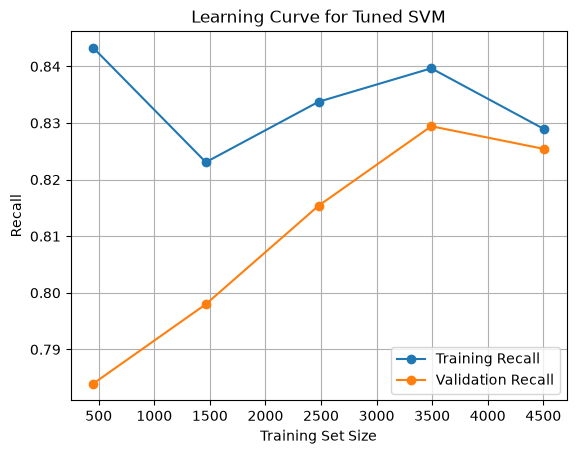

In [92]:
best_svm_model = svm_search.best_estimator_

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=best_svm_model,
    X=xtrain,
    y=ytrain,
    cv=cv,
    scoring="recall",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training Recall"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation Recall"
)

plt.xlabel("Training Set Size")
plt.ylabel("Recall")
plt.title("Learning Curve for Tuned SVM")
plt.legend()
plt.grid()
plt.show()

In [93]:
best_model = svm_search.best_estimator_

print("Selected Model: SVM")
print("Best Parameters:")
print(svm_search.best_params_)

Selected Model: SVM
Best Parameters:
{'classifier__C': 1, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}


In [94]:
y_pred = best_model.predict(xtest)
y_prob = best_model.predict_proba(xtest)[:, 1]

In [95]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

final_metrics = {
    "Accuracy": accuracy_score(ytest, y_pred),
    "Precision": precision_score(ytest, y_pred),
    "Recall": recall_score(ytest, y_pred),
    "F1 Score": f1_score(ytest, y_pred),
    "ROC-AUC": roc_auc_score(ytest, y_prob)
}

pd.DataFrame([final_metrics]).round(4)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,0.709,0.4721,0.8155,0.598,0.8338


In [96]:
print(classification_report(
    ytest,
    y_pred,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.91      0.67      0.77      1035
       Churn       0.47      0.82      0.60       374

    accuracy                           0.71      1409
   macro avg       0.69      0.74      0.69      1409
weighted avg       0.79      0.71      0.73      1409



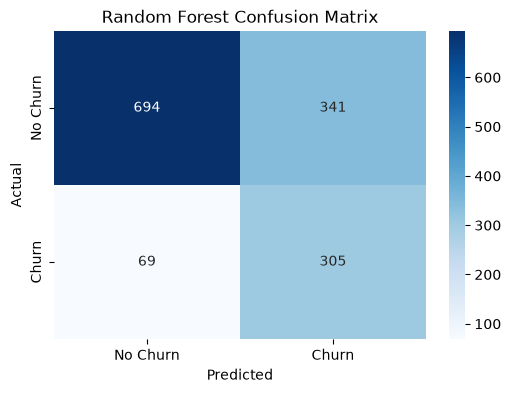

In [97]:
import seaborn as sns

cm = confusion_matrix(ytest, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [98]:
final_model = svm_search.best_estimator_

print("Final model selected:", final_model)

Final model selected: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('enc

In [99]:
import joblib

MODEL_PATH = BASE_DIR / "models" / "churn_v3.joblib"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(final_model, MODEL_PATH)

print("Final model saved at:", MODEL_PATH)

Final model saved at: /Users/apple/Desktop/timepass/RetailMind/models/churn_v3.joblib
